In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [2]:
# Step 1: Load data
# Reading the CSV file into a pandas DataFrame
data = pd.read_csv("C:\\Users\\Dell\\Downloads\\03. Placement Data.xls")

In [3]:
# Drop the 'Unnamed: 0' column if it exists to avoid feature mismatch
if 'Unnamed: 0' in data.columns:
    data = data.drop('Unnamed: 0', axis=1)

In [4]:
# Step 2: Preprocess data
# Check for missing values
print("Missing values:\n", data.isnull().sum())

Missing values:
 grade                  0
cgpa                   0
iq                     0
communication          0
technical_knowledge    0
placement              0
dtype: int64


In [5]:
# Encode categorical variable 'grade'
le = LabelEncoder()
data['grade'] = le.fit_transform(data['grade'])

In [6]:
# Step 3: Perform exploratory data analysis (EDA)
# Display basic statistics
print("\nDataset Info:")
print(data.info())
print("\nBasic Statistics:")
print(data.describe())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   grade                500 non-null    int32  
 1   cgpa                 500 non-null    float64
 2   iq                   500 non-null    int64  
 3   communication        500 non-null    int64  
 4   technical_knowledge  500 non-null    int64  
 5   placement            500 non-null    int64  
dtypes: float64(1), int32(1), int64(4)
memory usage: 21.6 KB
None

Basic Statistics:
            grade        cgpa          iq  communication  technical_knowledge  \
count  500.000000  500.000000  500.000000     500.000000           500.000000   
mean     1.110000    7.007540  109.786000       5.344000             5.626000   
std      0.967353    1.006612   17.363848       2.852707             2.810324   
min      0.000000    4.300000   80.000000       1.000000             1.0

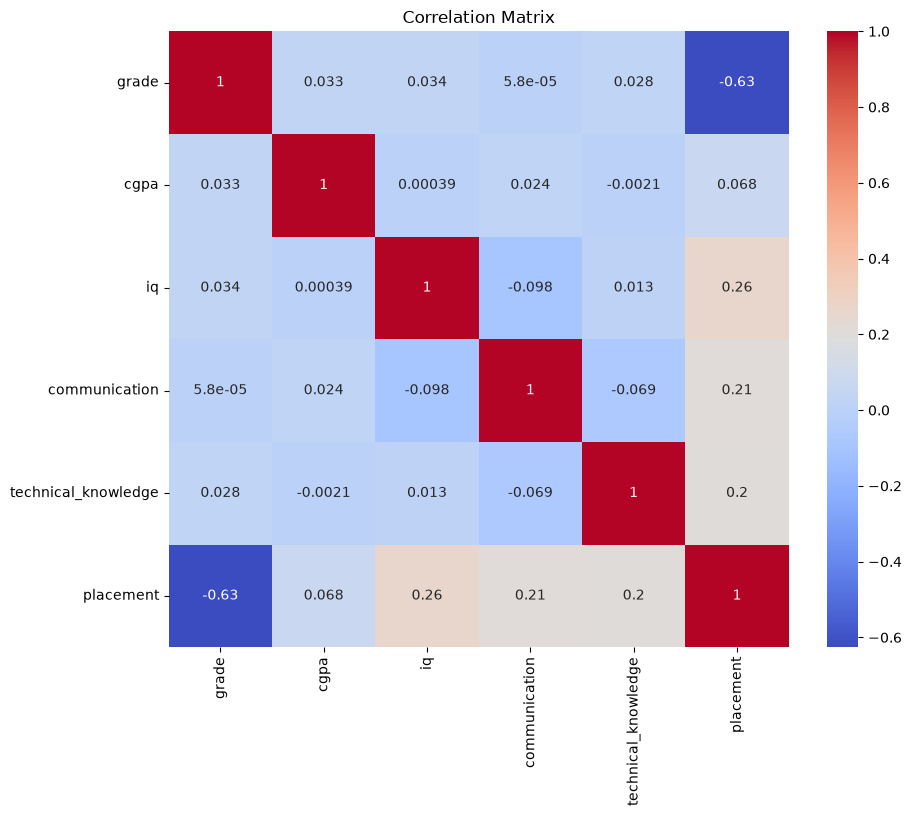

In [7]:
# Visualize correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.savefig('correlation_matrix.png')
plt.show()

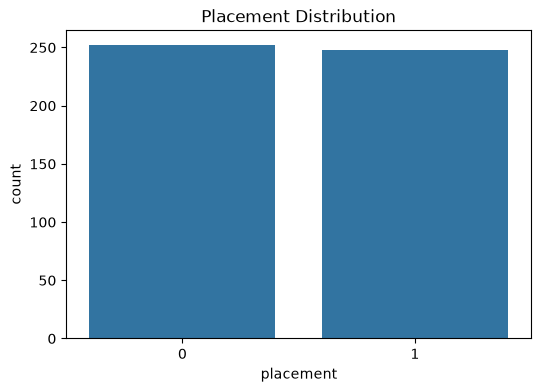

In [8]:
# Visualize placement distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='placement', data=data)
plt.title('Placement Distribution')
plt.savefig('placement_distribution.png')
plt.show()

In [9]:
# Step 4: Transform data
# Define features (X) and target (y)
X = data.drop('placement', axis=1)
y = data['placement']

In [10]:
# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [11]:
# Step 5: Split data into training and testing sets
# Using 80-20 split for training and testing
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [12]:
# Step 6: Train model
# Initialize and train Gaussian Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[201.,199.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.012e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 5)","[[ 0.65,-0.05,-0.24,-0.21,-0.2 ], [-0.65, 0.02, 0.22, 0.22, 0.19]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 5)","[[0.78,1.11,0.87,0.97,1.01], [0.39,0.87,0.99,0.97,0.94]]"


In [13]:
# Step 7: Evaluate model
# Make predictions on test set
y_pred = nb_model.predict(X_test)

In [14]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nInitial Model Accuracy:", accuracy)


Initial Model Accuracy: 0.83


In [15]:
# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82        51
           1       0.78      0.92      0.84        49

    accuracy                           0.83       100
   macro avg       0.84      0.83      0.83       100
weighted avg       0.84      0.83      0.83       100



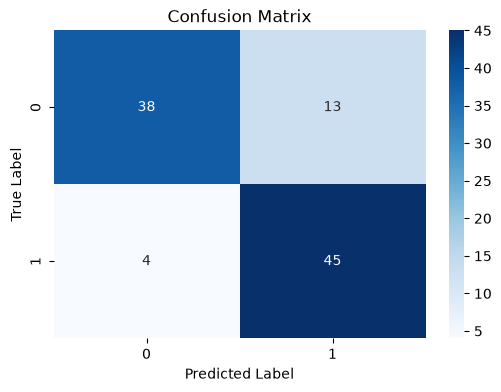

In [16]:
# Create and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig('confusion_matrix.png')
plt.show()

In [17]:
# Step 8: Tune hyperparameters
# Define parameter grid for GaussianNB (var_smoothing is the main parameter to tune)
param_grid = {
    'var_smoothing': np.logspace(0, -9, num=10)
}

In [18]:
# Perform grid search
grid_search = GridSearchCV(GaussianNB(), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GaussianNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'var_smoothing': array([1.e+00...e-08, 1.e-09])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fittin

In [19]:
# Get best model
best_model = grid_search.best_estimator_
print("\nBest Parameters:", grid_search.best_params_)
print("Best Cross-validation Score:", grid_search.best_score_)


Best Parameters: {'var_smoothing': 1.0}
Best Cross-validation Score: 0.8549999999999999


In [20]:
# Step 9: Evaluate tuned model
# Make predictions with tuned model
y_pred_tuned = best_model.predict(X_test)

In [21]:
# Calculate accuracy for tuned model
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
print("\nTuned Model Accuracy:", tuned_accuracy)
print("\nTuned Model Classification Report:")
print(classification_report(y_test, y_pred_tuned))


Tuned Model Accuracy: 0.83

Tuned Model Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82        51
           1       0.78      0.92      0.84        49

    accuracy                           0.83       100
   macro avg       0.84      0.83      0.83       100
weighted avg       0.84      0.83      0.83       100



In [22]:
# Step 10: Save model
# Save the trained model, scaler, and label encoder
joblib.dump(best_model, 'naive_bayes_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')
print("\nModel, scaler, and label encoder saved successfully")


Model, scaler, and label encoder saved successfully


In [23]:
# Step 11: Test the model on unseen data
# Create a sample unseen data point with the same features as training data
unseen_data = pd.DataFrame({
    'grade': ['A'],
    'cgpa': [7.5],
    'iq': [100],
    'communication': [8],
    'technical_knowledge': [7]
})

In [24]:
# Preprocess unseen data
unseen_data['grade'] = le.transform(unseen_data['grade'])
unseen_data_scaled = scaler.transform(unseen_data)

In [25]:
# Make prediction on unseen data
prediction = best_model.predict(unseen_data_scaled)
print("\nPrediction for unseen data:", "Placed" if prediction[0] == 1 else "Not Placed")


Prediction for unseen data: Placed


In [26]:
# Print prediction probability
proba = best_model.predict_proba(unseen_data_scaled)

In [27]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape
print("Prediction Probability [Not Placed, Placed]:", proba[0])

Prediction Probability [Not Placed, Placed]: [0.23874472 0.76125528]
